In [2]:
import pandas as pd
import numpy as np
import warnings

# Ignorar advertencias de Pandas para una salida más limpia
warnings.filterwarnings('ignore')

print("--- [INICIO DEL PROCESO] ---")

# --- PASO 1: Cargar, Limpiar y Preprocesar el Dataset ---

print("\n--- PASO 1: Cargando y Limpiando Datos ---")

try:
    # Cargar el archivo CSV
    df = pd.read_csv("ProductPriceIndex.csv")

    # 1. Convertir 'date' a formato datetime
    df['date'] = pd.to_datetime(df['date'])

    # 2. Limpiar 'averagespread'
    # Nos aseguramos de que sea string, luego reemplazamos y convertimos
    df['averagespread'] = df['averagespread'].astype(str).str.replace('%', '', regex=False)
    df['averagespread'] = pd.to_numeric(df['averagespread'], errors='coerce') / 100.0

    # 3. Limpiar todas las columnas de precios
    price_cols = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']

    for col in price_cols:
        # Asegurar que es string, quitar '$' y ','
        df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
        # Convertir a numérico
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # 4. Eliminar filas con datos nulos en las columnas clave
    key_cols = ['productname', 'date', 'farmprice', 'atlantaretail']
    df = df.dropna(subset=key_cols)

    print("Limpieza de datos exitosa.")

    # 5. Simplificar: Enfocarnos en UN producto
    PRODUCTO_OBJETIVO = "Strawberries" # Fresas
    df_product = df[df['productname'] == PRODUCTO_OBJETIVO].sort_values(by='date').copy()

    if df_product.empty:
        print(f"¡Error! No se encontraron datos para '{PRODUCTO_OBJETIVO}'. Saliendo.")
        exit()

    print(f"Datos filtrados para '{PRODUCTO_OBJETIVO}'. {len(df_product)} registros encontrados.")

except FileNotFoundError:
    print("Error: No se encontró el archivo 'ProductPriceIndex.csv'.")
    exit()
except Exception as e:
    print(f"Error durante la carga o limpieza: {e}")
    exit()

# --- PASO 2: Definir el MDP (Discretización) ---
# Q-Learning tabular necesita estados y acciones discretos (categorías).
# Vamos a crear "cubetas" (bins) para los precios.

print("\n--- PASO 2: Discretizando Estados y Acciones ---")

# 1. Definir ESTADOS (S)
# Usaremos 'farmprice' (precio de costo) como nuestro estado.
# Usamos qcut para crear 3 categorías con aprox. el mismo número de datos
df_product['estado'] = pd.qcut(df_product['farmprice'], q=3, labels=['Costo_Bajo', 'Costo_Medio', 'Costo_Alto'])

# 2. Definir ACCIONES (A)
# Usaremos 'atlantaretail' (precio de venta) como nuestra acción.
df_product['accion'] = pd.qcut(df_product['atlantaretail'], q=3, labels=['Venta_Baja', 'Venta_Media', 'Venta_Alta'])

# 3. Definir RECOMPENSAS (R)
# La recompensa es la ganancia de esa transacción
df_product['recompensa'] = df_product['atlantaretail'] - df_product['farmprice']

# 4. Definir el ESTADO SIGUIENTE (S')
# El estado siguiente es el 'estado' (costo) en el *siguiente* registro de tiempo.
# Usamos .shift(-1) para "mirar" una fila hacia adelante.
df_product['siguiente_estado'] = df_product['estado'].shift(-1)

# 5. Limpieza final
# El último registro tendrá un 'siguiente_estado' NaN, lo eliminamos.
# También eliminamos filas donde la discretización falló (si las hay).
df_product_mdp = df_product.dropna(subset=['estado', 'accion', 'recompensa', 'siguiente_estado'])

if df_product_mdp.empty:
    print("¡Error! No quedaron datos después de la discretización. Pruebe con otro producto o más datos.")
    exit()

print("Discretización completada. Datos listos para el Entorno.")
print(f"{len(df_product_mdp)} transiciones (s, a, R, s') creadas.")
# print(df_product_mdp[['estado', 'accion', 'recompensa', 'siguiente_estado']].head())


# --- PASO 3: Construir el Entorno (basado en el CSV) ---
# Esta es la "caja negra" que el agente Q-Learning consultará.
# Simula la "realidad" basándose en el historial de su dataset.

print("\n--- PASO 3: Construyendo el Entorno de Simulación ---")

def get_experience_from_data(estado, accion):
    """
    Simula una transacción consultando el historial (nuestro DataFrame).
    Dado un (estado, accion), busca qué pasó en la realidad.
    """

    # 1. Buscar en el historial todas las veces que (estado, accion) ocurrieron
    posibles_resultados = df_product_mdp[
        (df_product_mdp['estado'] == estado) &
        (df_product_mdp['accion'] == accion)
    ]

    if posibles_resultados.empty:
        # --- Penalización ---
        # Si el agente intenta una combinación (s, a) que NUNCA ocurrió
        # en el historial, le damos una recompensa negativa y no cambia de estado.
        # Esto le enseña a no probar cosas "imposibles" (según los datos).
        return -100.0, estado # Recompensa negativa, estado se mantiene
    else:
        # --- Muestreo ---
        # Si la combinación sí ocurrió, elegimos una de esas veces al azar.
        experiencia = posibles_resultados.sample(1).iloc[0]

        # Devolvemos la recompensa y el estado siguiente que *realmente* ocurrieron
        return experiencia['recompensa'], experiencia['siguiente_estado']

# Prueba rápida del entorno
# test_r, test_s_prime = get_experience_from_data('Costo_Medio', 'Venta_Media')
# print(f"Prueba del entorno ('Costo_Medio', 'Venta_Media') -> R: {test_r:.2f}, S': {test_s_prime}")


# --- PASO 4: Implementar y Entrenar el Agente Q-Learning ---

print("\n--- PASO 4: Entrenando al Agente Q-Learning ---")

# 1. Definir los estados y acciones únicos de nuestros datos
estados = df_product_mdp['estado'].unique().tolist()
acciones = df_product_mdp['accion'].unique().tolist()

# 2. Inicializar la Q-Table
# Filas = Estados, Columnas = Acciones, todo en 0.0
q_table = pd.DataFrame(0.0, index=estados, columns=acciones)

print("--- Q-Table Inicial (Vacía) ---")
print(q_table)
print("\n" + "="*30 + "\n")

# 3. Parámetros de Hiperparámetros
alpha = 0.1      # Tasa de Aprendizaje (qué tanto confiamos en la nueva info)
gamma = 0.9      # Factor de Descuento (qué tanto valoramos las recompensas futuras)
epsilon = 1.0    # Tasa de Exploración inicial (100% aleatorio al inicio)
min_epsilon = 0.01 # Tasa de Exploración mínima
decay_rate = 0.999 # Tasa de decaimiento de épsilon (más lento)

num_episodios = 10000 # Cuántas simulaciones de "prueba" haremos

# 4. Función de Política (Epsilon-Greedy)
def elegir_accion(estado):
    global epsilon
    if np.random.uniform(0, 1) < epsilon:
        # EXPLORACIÓN
        return np.random.choice(acciones)
    else:
        # EXPLOTACIÓN
        return q_table.loc[estado].idxmax()

# 5. Loop de Entrenamiento
print(f"Iniciando entrenamiento por {num_episodios} episodios...")

for episodio in range(num_episodios):

    # Empezamos cada "día" en un estado inicial aleatorio (sacado del historial)
    estado_actual = np.random.choice(estados)

    # 1. Elige una acción (Explora o Explota)
    accion = elegir_accion(estado_actual)

    # 2. Obtiene la experiencia del "Entorno" (nuestro CSV)
    recompensa, nuevo_estado = get_experience_from_data(estado_actual, accion)

    # 3. Actualización Q-Learning
    valor_q_antiguo = q_table.loc[estado_actual, accion]
    max_q_futuro = q_table.loc[nuevo_estado].max()

    td_target = recompensa + gamma * max_q_futuro
    td_error = td_target - valor_q_antiguo

    # Nueva Q-Value
    q_table.loc[estado_actual, accion] = valor_q_antiguo + alpha * td_error

    # 4. Decaimiento de Epsilon
    epsilon = max(min_epsilon, epsilon * decay_rate)

    if (episodio + 1) % 1000 == 0:
        print(f"Episodio: {episodio + 1}/{num_episodios}, Epsilon: {epsilon:.4f}")

# --- RESULTADOS ---

print("\n" + "="*30 + "\n")
print("--- Q-Table Final (Aprendida) ---")
print("Valores Q = 'Calidad' (recompensa futura esperada) de cada decisión")
print(q_table.round(2))

print("\n" + "="*30 + "\n")
print(f"--- Política Óptima para '{PRODUCTO_OBJETIVO}' ---")
print("La mejor acción (precio) a tomar en cada estado (costo)")
politica_optima = q_table.idxmax(axis=1)
print(politica_optima)
print("\n--- [PROCESO COMPLETADO] ---")

--- [INICIO DEL PROCESO] ---

--- PASO 1: Cargando y Limpiando Datos ---
Limpieza de datos exitosa.
Datos filtrados para 'Strawberries'. 973 registros encontrados.

--- PASO 2: Discretizando Estados y Acciones ---
Discretización completada. Datos listos para el Entorno.
972 transiciones (s, a, R, s') creadas.

--- PASO 3: Construyendo el Entorno de Simulación ---

--- PASO 4: Entrenando al Agente Q-Learning ---
--- Q-Table Inicial (Vacía) ---
             Venta_Baja  Venta_Alta  Venta_Media
Costo_Bajo          0.0         0.0          0.0
Costo_Medio         0.0         0.0          0.0
Costo_Alto          0.0         0.0          0.0


Iniciando entrenamiento por 10000 episodios...
Episodio: 1000/10000, Epsilon: 0.3677
Episodio: 2000/10000, Epsilon: 0.1352
Episodio: 3000/10000, Epsilon: 0.0497
Episodio: 4000/10000, Epsilon: 0.0183
Episodio: 5000/10000, Epsilon: 0.0100
Episodio: 6000/10000, Epsilon: 0.0100
Episodio: 7000/10000, Epsilon: 0.0100
Episodio: 8000/10000, Epsilon: 0.0100
Epis

--- [INICIO DEL PROCESO con GRÁFICOS] ---

--- PASO 1: Cargando y Limpiando Datos ---
Limpieza de datos exitosa.
Datos filtrados para 'Strawberries'. 973 registros encontrados.

--- PASO 2: Discretizando Estados y Acciones ---
972 transiciones (s, a, R, s') creadas.
Gráfico 'distribucion_estados.png' guardado.
Gráfico 'distribucion_acciones.png' guardado.

--- PASO 3: Construyendo el Entorno de Simulación ---
Función de entorno 'get_experience_from_data' lista.

--- PASO 4: Entrenando al Agente Q-Learning ---
Iniciando entrenamiento por 10000 episodios...
Entrenamiento completado.


--- PASO 5: Resultados Detallados y Gráficos ---
Gráfico 'curva_aprendizaje.png' guardado.
Gráfico 'decaimiento_epsilon.png' guardado.
Gráfico 'q_table_heatmap.png' guardado.


--- Q-Table Final (Aprendida) ---
Valores Q = 'Calidad' (recompensa futura esperada) de cada decisión
             Venta_Baja  Venta_Alta  Venta_Media
Costo_Bajo        16.80       17.95        17.18
Costo_Medio       16.09       16.

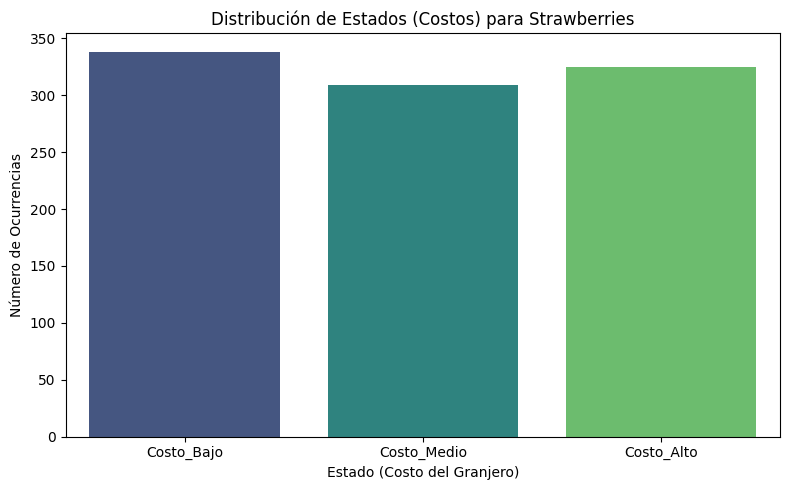

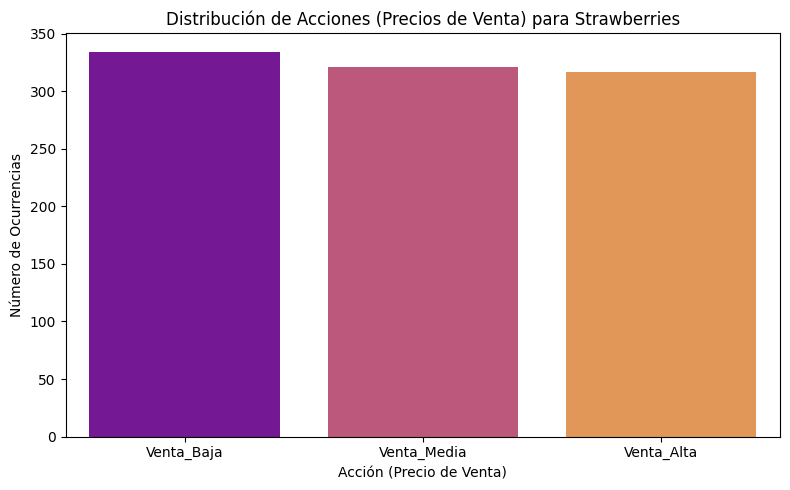

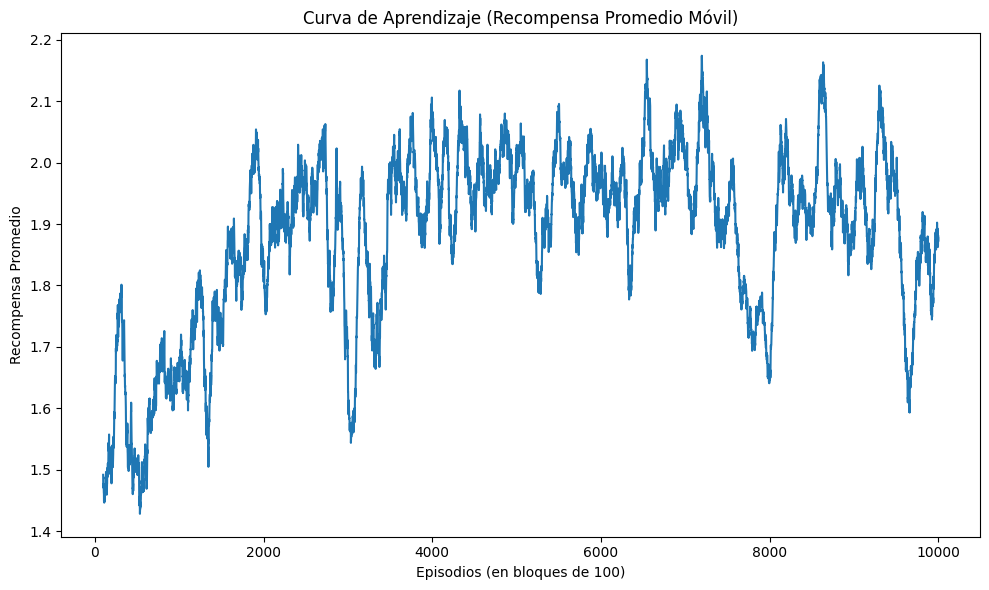

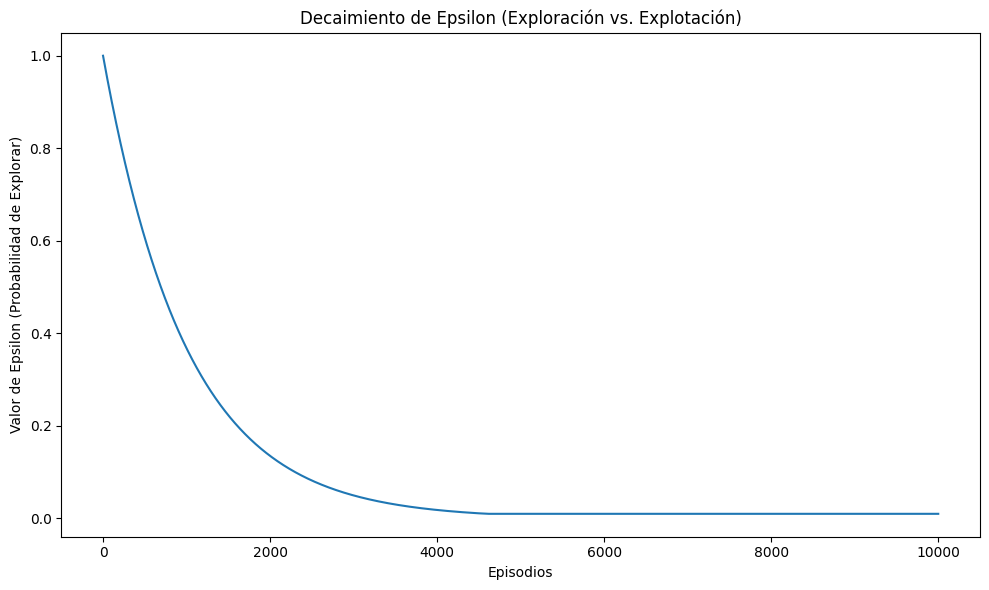

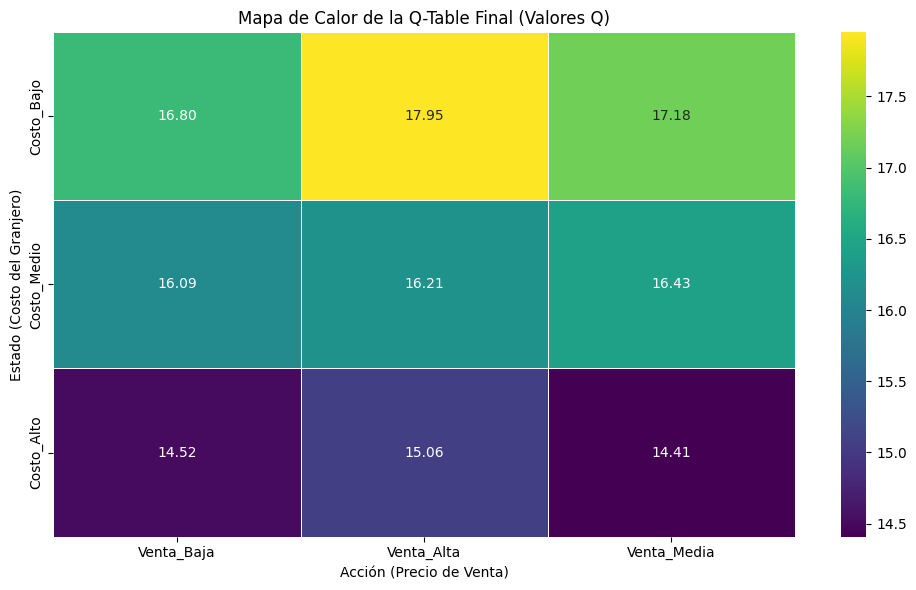

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignorar advertencias de Pandas para una salida más limpia
warnings.filterwarnings('ignore')

print("--- [INICIO DEL PROCESO con GRÁFICOS] ---")

# --- PASO 1: Cargar, Limpiar y Preprocesar el Dataset ---

print("\n--- PASO 1: Cargando y Limpiando Datos ---")

try:
    df = pd.read_csv("ProductPriceIndex.csv")
    df['date'] = pd.to_datetime(df['date'])
    df['averagespread'] = df['averagespread'].astype(str).str.replace('%', '', regex=False)
    df['averagespread'] = pd.to_numeric(df['averagespread'], errors='coerce') / 100.0

    price_cols = ['farmprice', 'atlantaretail', 'chicagoretail', 'losangelesretail', 'newyorkretail']
    for col in price_cols:
        df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

    key_cols = ['productname', 'date', 'farmprice', 'atlantaretail']
    df = df.dropna(subset=key_cols)
    print("Limpieza de datos exitosa.")

    PRODUCTO_OBJETIVO = "Strawberries" # Fresas
    df_product = df[df['productname'] == PRODUCTO_OBJETIVO].sort_values(by='date').copy()

    if df_product.empty:
        print(f"¡Error! No se encontraron datos para '{PRODUCTO_OBJETIVO}'. Saliendo.")
        exit()
    print(f"Datos filtrados para '{PRODUCTO_OBJETIVO}'. {len(df_product)} registros encontrados.")

except Exception as e:
    print(f"Error en Paso 1: {e}")
    exit()

# --- PASO 2: Definir el MDP (Discretización) ---

print("\n--- PASO 2: Discretizando Estados y Acciones ---")
try:
    df_product['estado'] = pd.qcut(df_product['farmprice'], q=3, labels=['Costo_Bajo', 'Costo_Medio', 'Costo_Alto'])
    df_product['accion'] = pd.qcut(df_product['atlantaretail'], q=3, labels=['Venta_Baja', 'Venta_Media', 'Venta_Alta'])
    df_product['recompensa'] = df_product['atlantaretail'] - df_product['farmprice']
    df_product['siguiente_estado'] = df_product['estado'].shift(-1)

    df_product_mdp = df_product.dropna(subset=['estado', 'accion', 'recompensa', 'siguiente_estado'])

    if df_product_mdp.empty:
        print("¡Error! No quedaron datos después de la discretización.")
        exit()
    print(f"{len(df_product_mdp)} transiciones (s, a, R, s') creadas.")

    # --- NUEVO: Gráficos de Distribución ---

    # Gráfico 1: Distribución de Estados (Costos)
    plt.figure(figsize=(8, 5))
    sns.countplot(x='estado', data=df_product_mdp, palette='viridis')
    plt.title(f'Distribución de Estados (Costos) para {PRODUCTO_OBJETIVO}')
    plt.ylabel('Número de Ocurrencias')
    plt.xlabel('Estado (Costo del Granjero)')
    plt.tight_layout()
    plt.savefig('distribucion_estados.png')
    print("Gráfico 'distribucion_estados.png' guardado.")

    # Gráfico 2: Distribución de Acciones (Precios de Venta)
    plt.figure(figsize=(8, 5))
    sns.countplot(x='accion', data=df_product_mdp, palette='plasma')
    plt.title(f'Distribución de Acciones (Precios de Venta) para {PRODUCTO_OBJETIVO}')
    plt.ylabel('Número de Ocurrencias')
    plt.xlabel('Acción (Precio de Venta)')
    plt.tight_layout()
    plt.savefig('distribucion_acciones.png')
    print("Gráfico 'distribucion_acciones.png' guardado.")

except Exception as e:
    print(f"Error en Paso 2: {e}")
    exit()

# --- PASO 3: Construir el Entorno (basado en el CSV) ---

print("\n--- PASO 3: Construyendo el Entorno de Simulación ---")

def get_experience_from_data(estado, accion):
    posibles_resultados = df_product_mdp[
        (df_product_mdp['estado'] == estado) &
        (df_product_mdp['accion'] == accion)
    ]
    if posibles_resultados.empty:
        return -100.0, estado # Penalización fuerte por acción "imposible"
    else:
        experiencia = posibles_resultados.sample(1).iloc[0]
        return experiencia['recompensa'], experiencia['siguiente_estado']

print("Función de entorno 'get_experience_from_data' lista.")

# --- PASO 4: Implementar y Entrenar el Agente Q-Learning ---

print("\n--- PASO 4: Entrenando al Agente Q-Learning ---")

estados = df_product_mdp['estado'].unique().tolist()
acciones = df_product_mdp['accion'].unique().tolist()
q_table = pd.DataFrame(0.0, index=estados, columns=acciones)

# Parámetros
alpha = 0.1
gamma = 0.9
epsilon = 1.0
min_epsilon = 0.01
decay_rate = 0.999
num_episodios = 10000

# --- NUEVO: Listas para guardar el historial ---
recompensas_historial = []
epsilon_historial = []

def elegir_accion(estado):
    global epsilon
    if np.random.uniform(0, 1) < epsilon:
        return np.random.choice(acciones)
    else:
        return q_table.loc[estado].idxmax()

# Loop de Entrenamiento
print(f"Iniciando entrenamiento por {num_episodios} episodios...")
for episodio in range(num_episodios):
    estado_actual = np.random.choice(estados)
    accion = elegir_accion(estado_actual)
    recompensa, nuevo_estado = get_experience_from_data(estado_actual, accion)

    # Actualización Q-Learning
    valor_q_antiguo = q_table.loc[estado_actual, accion]
    max_q_futuro = q_table.loc[nuevo_estado].max()
    td_target = recompensa + gamma * max_q_futuro
    nuevo_valor_q = valor_q_antiguo + alpha * (td_target - valor_q_antiguo)
    q_table.loc[estado_actual, accion] = nuevo_valor_q

    # --- NUEVO: Guardar historial ---
    recompensas_historial.append(recompensa)
    epsilon_historial.append(epsilon)

    epsilon = max(min_epsilon, epsilon * decay_rate)

print("Entrenamiento completado.")

# --- PASO 5: Resultados Detallados y Gráficos ---

print("\n" + "="*40 + "\n")
print("--- PASO 5: Resultados Detallados y Gráficos ---")

# --- Gráfico 3: Curva de Aprendizaje (Recompensa Promedio Móvil) ---
# Calculamos un promedio móvil para suavizar la curva
recompensas_movil = pd.Series(recompensas_historial).rolling(window=int(num_episodios/100)).mean()

plt.figure(figsize=(10, 6))
plt.plot(recompensas_movil)
plt.title('Curva de Aprendizaje (Recompensa Promedio Móvil)')
plt.xlabel(f'Episodios (en bloques de {int(num_episodios/100)})')
plt.ylabel('Recompensa Promedio')
plt.tight_layout()
plt.savefig('curva_aprendizaje.png')
print("Gráfico 'curva_aprendizaje.png' guardado.")

# --- Gráfico 4: Decaimiento de Epsilon (Exploración) ---
plt.figure(figsize=(10, 6))
plt.plot(epsilon_historial)
plt.title('Decaimiento de Epsilon (Exploración vs. Explotación)')
plt.xlabel('Episodios')
plt.ylabel('Valor de Epsilon (Probabilidad de Explorar)')
plt.tight_layout()
plt.savefig('decaimiento_epsilon.png')
print("Gráfico 'decaimiento_epsilon.png' guardado.")

# --- Gráfico 5: Mapa de Calor (Heatmap) de la Q-Table Final ---
plt.figure(figsize=(10, 6))
sns.heatmap(q_table, annot=True, fmt='.2f', cmap='viridis', linewidths=.5)
plt.title('Mapa de Calor de la Q-Table Final (Valores Q)')
plt.xlabel('Acción (Precio de Venta)')
plt.ylabel('Estado (Costo del Granjero)')
plt.tight_layout()
plt.savefig('q_table_heatmap.png')
print("Gráfico 'q_table_heatmap.png' guardado.")

# --- Resultados en Texto (como antes) ---
print("\n" + "="*40 + "\n")
print("--- Q-Table Final (Aprendida) ---")
print("Valores Q = 'Calidad' (recompensa futura esperada) de cada decisión")
print(q_table.round(2))

print("\n" + "="*40 + "\n")
print(f"--- Política Óptima para '{PRODUCTO_OBJETIVO}' ---")
print("La mejor acción (precio) a tomar en cada estado (costo)")
politica_optima = q_table.idxmax(axis=1)
print(politica_optima)
print("\n--- [PROCESO COMPLETADO] ---")